## EV charging data: exploratory data analysis (EDA)
Input: ChargingRecords_preprocessed.csv (output of the Phase 1 cleaning notebook). Run the cells top to bottom.

Sections:

Load data and create time features
Demand distribution and outliers
Usage by hour, weekday, month and charger type
Location and charging-company comparisons
Correlation analysis
Check the dominant user ID
Summary of findings

# 1. Load data and create time features

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=0.9)
BLUE, ORANGE = "#2a6f97", "#e07a1f"

df = pd.read_csv(r"D:\HCL_PROJECTS\EV_Charging_Demand_Analysis\ChargingRecords_preprocessed.csv", parse_dates=["StartDatetime", "EndDatetime"])
print(df.shape)
df.head()

(72031, 30)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,...,Month,MonthName,YearMonth,Weekday,DayOfWeek,IsWeekend,StartHour,EndHour,CrossesMidnight,TimeOfDay
0,102,291,1,public institution,0,30-09-2021,17:14:26,01-10-2021,01:21:28,2021-09-30 17:14:00,...,9,September,2021-09,Thursday,3,False,17,1,True,Afternoon
1,104,191,1,resort,0,30-09-2021,18:22:36,01-10-2021,02:21:03,2021-09-30 18:22:00,...,9,September,2021-09,Thursday,3,False,18,2,True,Evening
2,105,320,1,camping,0,30-09-2021,18:57:46,01-10-2021,00:44:59,2021-09-30 18:57:00,...,9,September,2021-09,Thursday,3,False,18,0,True,Evening
3,0,433,1,camping,0,30-09-2021,19:52:22,01-10-2021,00:21:51,2021-09-30 19:52:00,...,9,September,2021-09,Thursday,3,False,19,0,True,Evening
4,391,250,1,public area,0,30-09-2021,20:48:46,01-10-2021,03:35:11,2021-09-30 20:48:00,...,9,September,2021-09,Thursday,3,False,20,3,True,Evening


In [2]:
df

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,...,Month,MonthName,YearMonth,Weekday,DayOfWeek,IsWeekend,StartHour,EndHour,CrossesMidnight,TimeOfDay
0,102,291,1,public institution,0,30-09-2021,17:14:26,01-10-2021,01:21:28,2021-09-30 17:14:00,...,9,September,2021-09,Thursday,3,False,17,1,True,Afternoon
1,104,191,1,resort,0,30-09-2021,18:22:36,01-10-2021,02:21:03,2021-09-30 18:22:00,...,9,September,2021-09,Thursday,3,False,18,2,True,Evening
2,105,320,1,camping,0,30-09-2021,18:57:46,01-10-2021,00:44:59,2021-09-30 18:57:00,...,9,September,2021-09,Thursday,3,False,18,0,True,Evening
3,0,433,1,camping,0,30-09-2021,19:52:22,01-10-2021,00:21:51,2021-09-30 19:52:00,...,9,September,2021-09,Thursday,3,False,19,0,True,Evening
4,391,250,1,public area,0,30-09-2021,20:48:46,01-10-2021,03:35:11,2021-09-30 20:48:00,...,9,September,2021-09,Thursday,3,False,20,3,True,Evening
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72026,0,217,1,hotel,0,30-09-2022,21:49:59,30-09-2022,22:42:45,2022-09-30 21:49:00,...,9,September,2022-09,Friday,4,False,21,22,False,Evening
72027,69,967,0,public parking lot,1,30-09-2022,22:10:38,30-09-2022,22:40:20,2022-09-30 22:10:00,...,9,September,2022-09,Friday,4,False,22,22,False,Late evening
72028,0,219,1,public area,0,30-09-2022,22:31:03,30-09-2022,23:25:59,2022-09-30 22:31:00,...,9,September,2022-09,Friday,4,False,22,23,False,Late evening
72029,531,66,1,resort,0,30-09-2022,22:37:45,30-09-2022,23:52:59,2022-09-30 22:37:00,...,9,September,2022-09,Friday,4,False,22,23,False,Late evening


In [3]:
df["Hour"]    = df["StartDatetime"].dt.hour
df["Weekday"] = df["StartDatetime"].dt.day_name()
df["Month"]   = df["StartDatetime"].dt.to_period("M").astype(str)   # keeps 2021 and 2022 apart
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

print("Date range:", df["StartDatetime"].min(), "->", df["StartDatetime"].max())
print("Users:", df["UserID"].nunique(), "| Chargers:", df["ChargerID"].nunique())

Date range: 2021-09-30 17:14:00 -> 2022-09-30 23:11:00
Users: 2320 | Chargers: 2115


# 2. Demand distribution and outlier analysis

In [4]:
df["Demand"].describe(percentiles=[.5, .9, .95, .99]).round(2)

count    72031.00
mean        17.57
std         13.45
min          0.01
50%         14.26
90%         37.61
95%         46.23
99%         58.93
max         97.00
Name: Demand, dtype: float64

In [5]:
print("Skewness:", round(df["Demand"].skew(), 2))

q1, q3 = df["Demand"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
z = (df["Demand"] - df["Demand"].mean()) / df["Demand"].std()

df["OutlierIQR"] = df["Demand"] > upper
df["OutlierZ"]   = z.abs() > 3

print(f"IQR upper limit: {upper:.2f}")
print(f"IQR outliers:     {df['OutlierIQR'].sum()} ({df['OutlierIQR'].mean():.1%})")
print(f"Z-score outliers: {df['OutlierZ'].sum()} ({df['OutlierZ'].mean():.1%})")
print(f"Share of total demand from IQR outliers: {df.loc[df['OutlierIQR'], 'Demand'].sum() / df['Demand'].sum():.1%}")

Skewness: 1.2
IQR upper limit: 46.45
IQR outliers:     3513 (4.9%)
Z-score outliers: 886 (1.2%)
Share of total demand from IQR outliers: 15.0%


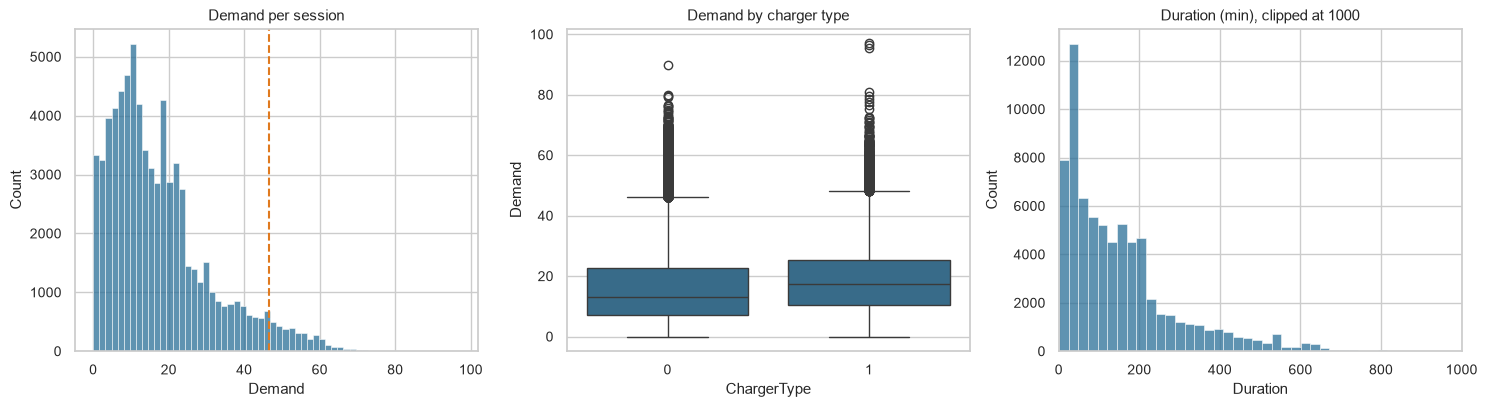

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

sns.histplot(df["Demand"], bins=60, color=BLUE, ax=ax[0])
ax[0].axvline(upper, color=ORANGE, ls="--")
ax[0].set_title("Demand per session")

sns.boxplot(data=df, x="ChargerType", y="Demand", color=BLUE, ax=ax[1])
ax[1].set_title("Demand by charger type")

sns.histplot(df["Duration"], bins=60, color=BLUE, ax=ax[2])
ax[2].set_xlim(0, 1000)
ax[2].set_title("Duration (min), clipped at 1000")

plt.tight_layout()
plt.show()

In [7]:
# Where do the outliers come from? (outlier rate per location)
(df.groupby("Location")["OutlierIQR"].mean().sort_values(ascending=False).mul(100).round(1)
   .rename("Outlier %").to_frame())

,Outlier %
Location,
bus garage,17.2
camping,13.4
accommodation,11.4
apartment,6.2
restaurant,6.2
public area,5.5
market,5.1
resort,4.8
public institution,4.7


# 3. Usage by hour, weekday, month and charger type

In [8]:
by_hour = df.groupby("Hour")["Demand"].agg(["count", "mean"]).round(2)
by_hour["share_%"] = (by_hour["count"] / len(df) * 100).round(1)
by_hour

,count,mean,share_%
Hour,,,
0,908,26.67,1.3
1,446,25.33,0.6
2,195,25.49,0.3
3,133,20.36,0.2
4,189,18.32,0.3
5,543,17.40,0.8
6,1209,16.99,1.7
7,2271,16.92,3.2
8,4106,17.63,5.7


In [9]:
by_weekday = df.groupby("Weekday")["Demand"].agg(["count", "mean"]).reindex(weekday_order).round(2)
by_month   = df.groupby("Month")["Demand"].agg(["count", "mean"]).round(2)
display(by_weekday)
display(by_month)

,count,mean
Weekday,,
Monday,10223,17.46
Tuesday,10540,17.22
Wednesday,10760,17.66
Thursday,10924,17.76
Friday,10858,17.42
Saturday,9834,17.55
Sunday,8892,17.96


,count,mean
Month,,
2021-09,19,30.48
2021-10,3863,16.68
2021-11,4228,16.86
2021-12,4788,17.62
2022-01,6213,17.53
2022-02,5744,17.84
2022-03,5887,17.58
2022-04,5938,17.52
2022-05,6635,17.35


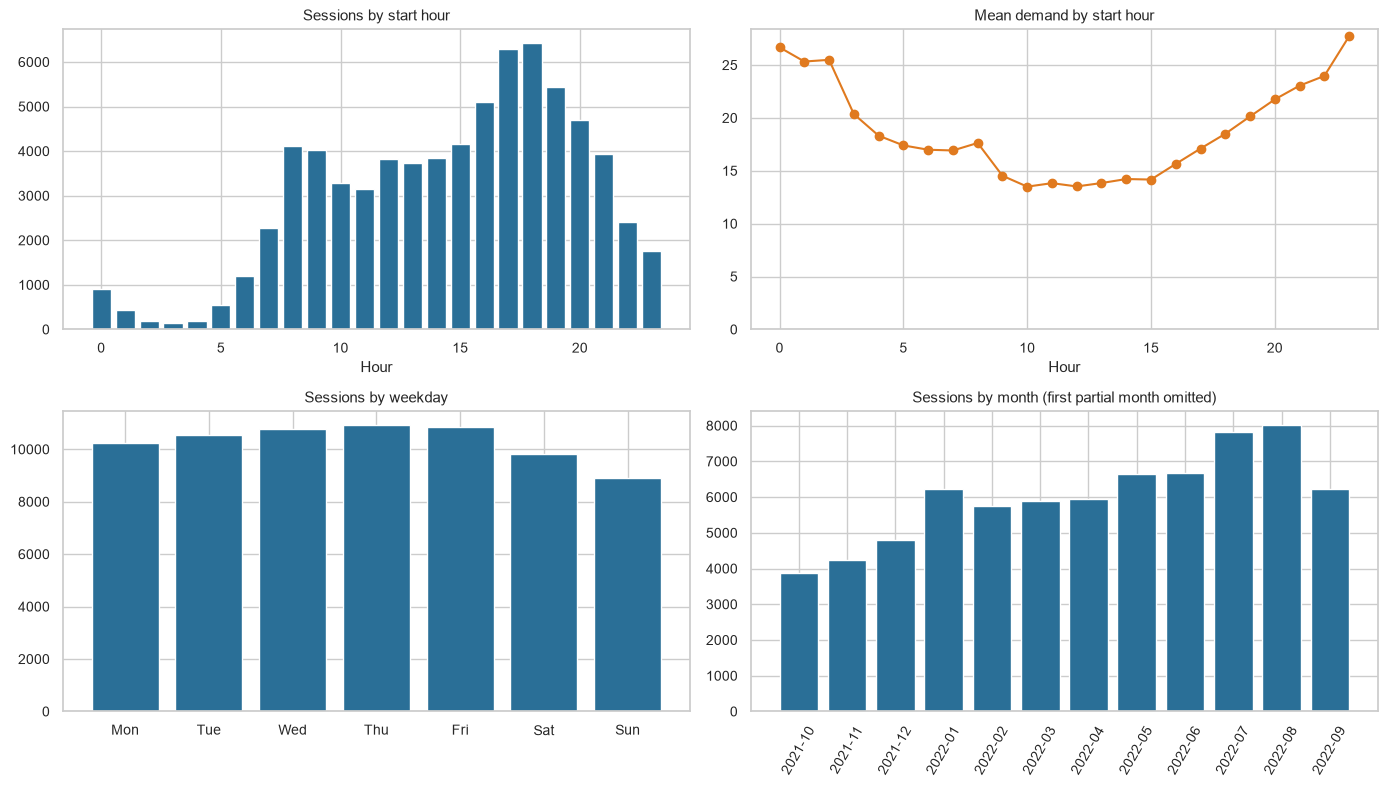

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))

ax[0, 0].bar(by_hour.index, by_hour["count"], color=BLUE)
ax[0, 0].set_title("Sessions by start hour"); ax[0, 0].set_xlabel("Hour")

ax[0, 1].plot(by_hour.index, by_hour["mean"], marker="o", color=ORANGE)
ax[0, 1].set_title("Mean demand by start hour"); ax[0, 1].set_xlabel("Hour"); ax[0, 1].set_ylim(0, None)

ax[1, 0].bar([d[:3] for d in weekday_order], by_weekday["count"], color=BLUE)
ax[1, 0].set_title("Sessions by weekday")

m = by_month.iloc[1:]      # first month has only a few sessions (data starts on 30 Sep 2021)
ax[1, 1].bar(m.index, m["count"], color=BLUE)
ax[1, 1].set_title("Sessions by month (first partial month omitted)")
ax[1, 1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

In [11]:
by_type = df.groupby("ChargerType").agg(
    sessions=("Demand", "count"),
    mean_demand=("Demand", "mean"),
    median_demand=("Demand", "median"),
    mean_duration_min=("Duration", "mean"),
    outlier_rate=("OutlierIQR", "mean"),
).round(2)
by_type["demand_per_min"] = (df.groupby("ChargerType").apply(lambda g: (g["Demand"] / g["Duration"]).median())).round(3)
by_type

,sessions,mean_demand,median_demand,mean_duration_min,outlier_rate,demand_per_min
ChargerType,,,,,,
0,57321,17.14,13.20,182.20,0.05,0.109
1,14710,19.23,17.34,36.59,0.04,0.547


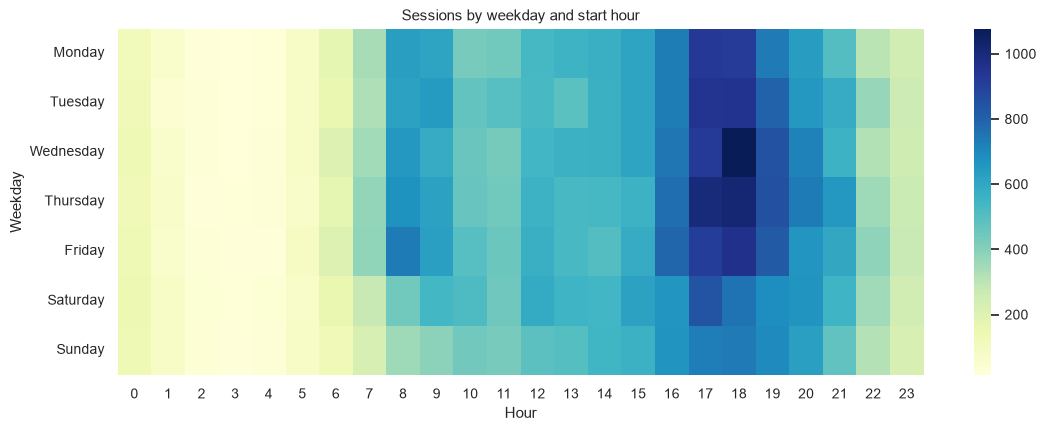

In [12]:
# Hour x weekday heatmap of session counts
pivot = df.pivot_table(index="Weekday", columns="Hour", values="Demand", aggfunc="count").reindex(weekday_order)
plt.figure(figsize=(13, 4.5))
sns.heatmap(pivot, cmap="YlGnBu")
plt.title("Sessions by weekday and start hour")
plt.show()

# 4. Location and charging-company comparisons

In [13]:
by_loc = (df.groupby("Location")
            .agg(sessions=("Demand", "count"),
                 mean_demand=("Demand", "mean"),
                 median_demand=("Demand", "median"),
                 mean_duration_min=("Duration", "mean"),
                 total_demand=("Demand", "sum"),
                 outlier_rate=("OutlierIQR", "mean"))
            .sort_values("mean_demand", ascending=False).round(2))
by_loc["share_of_total_demand_%"] = (by_loc["total_demand"] / by_loc["total_demand"].sum() * 100).round(1)
by_loc

,sessions,mean_demand,median_demand,mean_duration_min,total_demand,outlier_rate,share_of_total_demand_%
Location,,,,,,,
accommodation,185,29.37,28.80,270.17,5433.37,0.11,0.4
bus garage,29,28.59,29.91,30.62,829.04,0.17,0.1
camping,1620,25.67,23.66,245.14,41581.71,0.13,3.3
apartment,13883,18.81,14.50,206.21,261115.79,0.06,20.6
public area,13940,18.04,14.67,134.11,251480.98,0.05,19.9
restaurant,2214,17.86,13.81,156.98,39548.80,0.06,3.1
public institution,6961,17.55,14.61,121.31,122169.57,0.05,9.7
resort,8705,17.47,14.30,173.08,152093.67,0.05,12.0
public parking lot,3364,17.34,16.13,50.60,58332.69,0.02,4.6


In [14]:
by_company = df.groupby("ChargerCompany").agg(
    sessions=("Demand", "count"),
    chargers=("ChargerID", "nunique"),
    mean_demand=("Demand", "mean"),
    median_demand=("Demand", "median"),
    mean_duration_min=("Duration", "mean"),
).round(2)
display(by_company)

# Company 1 only runs charger type 0, so compare company and type together
df.groupby(["ChargerCompany", "ChargerType"]).agg(
    sessions=("Demand", "count"),
    mean_demand=("Demand", "mean"),
    mean_duration_min=("Duration", "mean"),
).round(2)

,sessions,chargers,mean_demand,median_demand,mean_duration_min
ChargerCompany,,,,,
0,26838,1826,16.84,13.44,105.28
1,45193,289,18.00,14.79,180.48


sessions  mean_demand  mean_duration_min
ChargerCompany ChargerType                                          
0              0               12128        13.95             188.59
               1               14710        19.23              36.59
1              0               45193        18.00             180.48

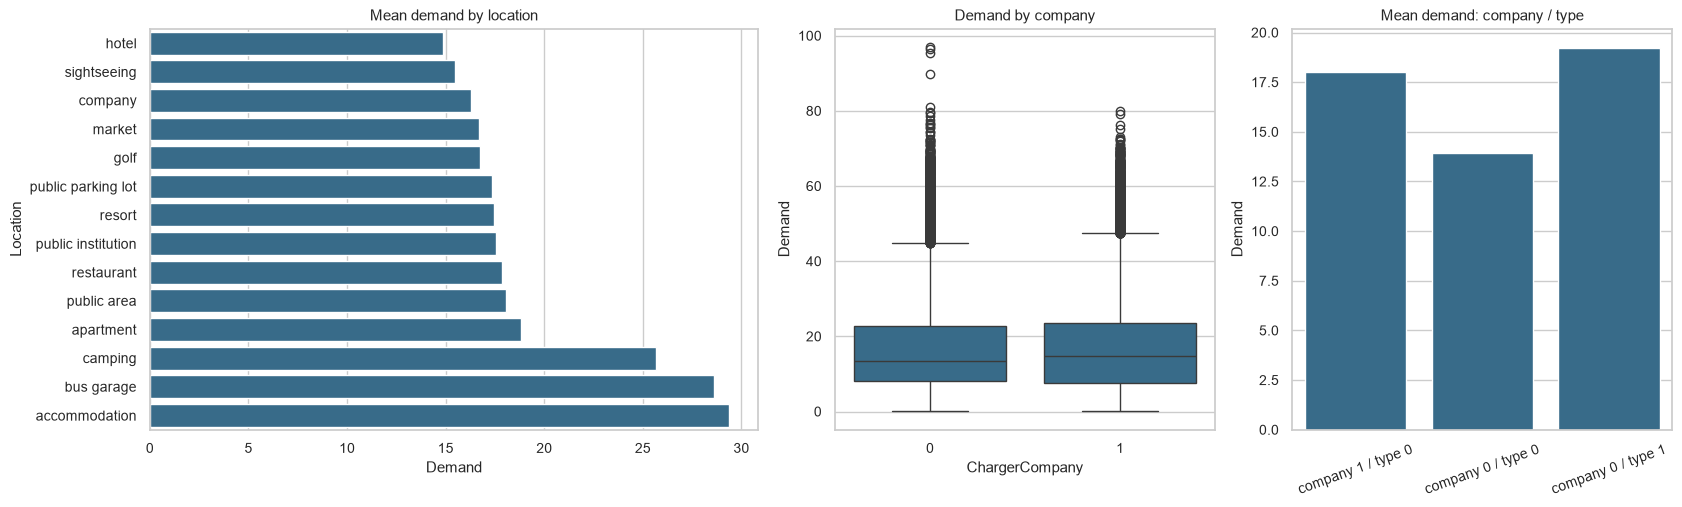

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.6, 1, 1]})

order = df.groupby("Location")["Demand"].mean().sort_values().index
sns.barplot(data=df, y="Location", x="Demand", order=order, color=BLUE, errorbar=None, ax=ax[0])
ax[0].set_title("Mean demand by location")

sns.boxplot(data=df, x="ChargerCompany", y="Demand", color=BLUE, ax=ax[1])
ax[1].set_title("Demand by company")

df["Group"] = "company " + df["ChargerCompany"].astype(str) + " / type " + df["ChargerType"].astype(str)
sns.barplot(data=df, x="Group", y="Demand", color=BLUE, errorbar=None, ax=ax[2])
ax[2].set_title("Mean demand: company / type"); ax[2].set_xlabel(""); ax[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

# 5. Correlation analysis

In [16]:
num_cols = ["Demand", "Duration", "ElapsedMin", "IdleMin", "Hour", "ChargerType", "ChargerCompany"]
pd.DataFrame({
    "pearson":  df[num_cols].corr()["Demand"],
    "spearman": df[num_cols].corr(method="spearman")["Demand"],
}).round(2)

,pearson,spearman
Demand,1.00,1.00
Duration,0.66,0.64
ElapsedMin,0.60,0.63
IdleMin,-0.00,0.02
Hour,0.13,0.16
ChargerType,0.06,0.11
ChargerCompany,0.04,0.02


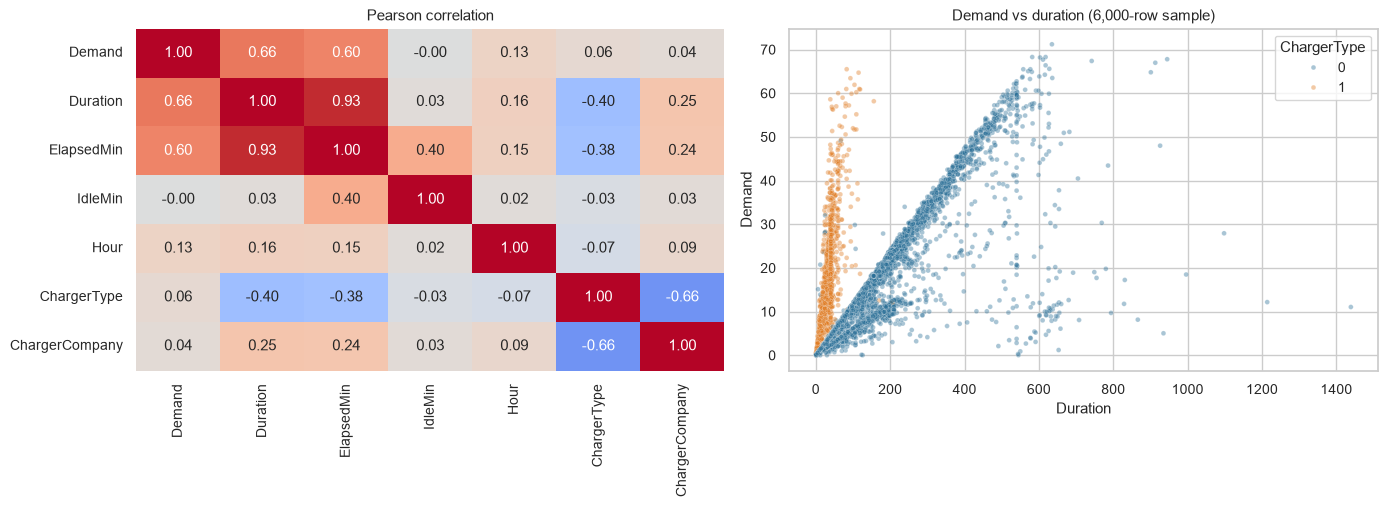

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))

sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, cbar=False, ax=ax[0])
ax[0].set_title("Pearson correlation")

sample = df.sample(6000, random_state=1)      # sample keeps the plot readable
sns.scatterplot(data=sample, x="Duration", y="Demand", hue="ChargerType", palette=[BLUE, ORANGE], alpha=0.4, s=12, ax=ax[1])
ax[1].set_title("Demand vs duration (6,000-row sample)")

plt.tight_layout()
plt.show()

# 6. Check the dominant user ID

In [18]:
counts = df["UserID"].value_counts()
top_id = counts.index[0]
print("Top user IDs:", counts.head(5).to_dict())
print(f"UserID {top_id}: {counts.iloc[0] / len(df):.1%} of all sessions, {df.loc[df['UserID'] == top_id, 'ChargerID'].nunique()} different chargers")

is_top = df["UserID"] == top_id
print("\nShare of company 1 sessions from this ID:", round((is_top & (df["ChargerCompany"] == 1)).sum() / (df["ChargerCompany"] == 1).sum(), 3))

compare = pd.DataFrame({
    "all":        df.groupby("ChargerCompany")["Demand"].mean(),
    "without_id": df[~is_top].groupby("ChargerCompany")["Demand"].mean(),
}).round(2)
compare.index.name = "ChargerCompany (mean demand)"
compare

Top user IDs: {0: 31175, 31: 351, 95: 347, 179: 337, 40: 323}
UserID 0: 43.3% of all sessions, 309 different chargers

Share of company 1 sessions from this ID: 0.651


,all,without_id
ChargerCompany (mean demand),,
0,16.84,16.86
1,18.00,20.28


In [19]:
# Do the main patterns hold without this ID?
others = df[~is_top]
print("Top start hours (all):        ", df["Hour"].value_counts().head(3).to_dict())
print("Top start hours (without ID): ", others["Hour"].value_counts().head(3).to_dict())
print("Demand~Duration correlation (all / without ID):",
      round(df[["Demand", "Duration"]].corr().iloc[0, 1], 2), "/", round(others[["Demand", "Duration"]].corr().iloc[0, 1], 2))

Top start hours (all):         {18: 6425, 17: 6286, 19: 5441}
Top start hours (without ID):  {17: 3710, 18: 3379, 16: 3091}
Demand~Duration correlation (all / without ID): 0.66 / 0.53


# 7. Summary of findings

In [ ]:
Demand and outliers

Demand per session is right-skewed (skewness about 1.2): median 14.3, mean 17.6, maximum 97.
The IQR rule flags about 4.9% of sessions (limit about 46.5). They make up about 15% of total demand, so they look like genuine heavy sessions and are better kept than removed.
Outliers are most common at camping, accommodation and apartments, and rare at hotels, sightseeing sites and public parking lots.
Time patterns

Sessions peak from 17:00 to 19:00, with a smaller morning bump at 08:00 to 09:00, and are lowest between 02:00 and 04:00.
Sessions starting overnight are few but large; sessions starting around midday are the smallest.
Weekdays are flat, and weekends are quieter (Sunday is the lowest). Mean demand barely changes by weekday.
Sessions grow from late 2021 to mid 2022 while mean demand stays steady, so growth comes from more sessions, not bigger ones.
Charger type, company and location

Charger type 1 sessions are much shorter and use far more demand per minute (about 5 times type 0), which suggests a fast charger. The data does not confirm what the codes mean.
Company 1 runs only type 0 chargers, so company comparisons are partly charger-type comparisons.
Accommodation, bus garages and camping have the highest mean demand per session; hotels and sightseeing sites have the lowest. Apartments and public areas carry the largest share of total demand.
Relationships

Demand is strongly linked to duration (about 0.66) and to plugged-in time (about 0.60). Time of day, charger type and company have weak linear links.
Type 0 sessions follow a straight line of demand against duration, and a scatter of long, low-demand sessions sits below it. Type 1 sessions form a separate steep cluster.
Data caveat

One UserID (0) makes up about 43% of sessions, mostly on company 1 chargers. Treat it separately for any user-level analysis. Without it, the company gap widens, the evening peak holds but shifts an hour earlier (16:00 to 18:00), and the location ranking stays the same.